In [2]:
import pandas as pd

df = pd.read_csv("predicting_electric_vehicle_dataset.csv")

In [3]:
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [5]:
df.shape

(668665, 15)

In [4]:
df.nunique()

id                             668665
Age                                45
Annual_Income_USD               13214
Daily_Commute_km                  805
Number_of_Cars_Owned                4
Charging_Stations_Near_Home        15
Charging_Stations_Near_Work        20
Environmental_Concern_Level         5
Gender                              3
City_Type                           3
Current_Car_Type                    4
Home_Charging_Possible              2
Subsidy_Available                   2
Range_Anxiety_Level                 3
Will_Buy_EV                         2
dtype: int64

In [6]:
df.nunique(dropna=False)

id                             668665
Age                                45
Annual_Income_USD               13214
Daily_Commute_km                  805
Number_of_Cars_Owned                4
Charging_Stations_Near_Home        15
Charging_Stations_Near_Work        20
Environmental_Concern_Level         5
Gender                              3
City_Type                           3
Current_Car_Type                    4
Home_Charging_Possible              2
Subsidy_Available                   2
Range_Anxiety_Level                 3
Will_Buy_EV                         2
dtype: int64

In [9]:
for col in df.columns:
  if df[col].nunique() <= 10:
    print(f"{col}: {df[col].unique()}")

Number_of_Cars_Owned: [2 1 4 3]
Environmental_Concern_Level: [1. 4. 5. 3. 2.]
Gender: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
City_Type: <StringArray>
['Suburban', 'Rural', 'Urban']
Length: 3, dtype: str
Current_Car_Type: <StringArray>
['Sedan', 'SUV', 'Hatchback', 'Truck']
Length: 4, dtype: str
Home_Charging_Possible: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Subsidy_Available: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Range_Anxiety_Level: <StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
Will_Buy_EV: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

In [11]:
df.isnull().sum()

id                             0
Age                            0
Annual_Income_USD              0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Environmental_Concern_Level    0
Gender                         0
City_Type                      0
Current_Car_Type               0
Home_Charging_Possible         0
Subsidy_Available              0
Range_Anxiety_Level            0
Will_Buy_EV                    0
dtype: int64

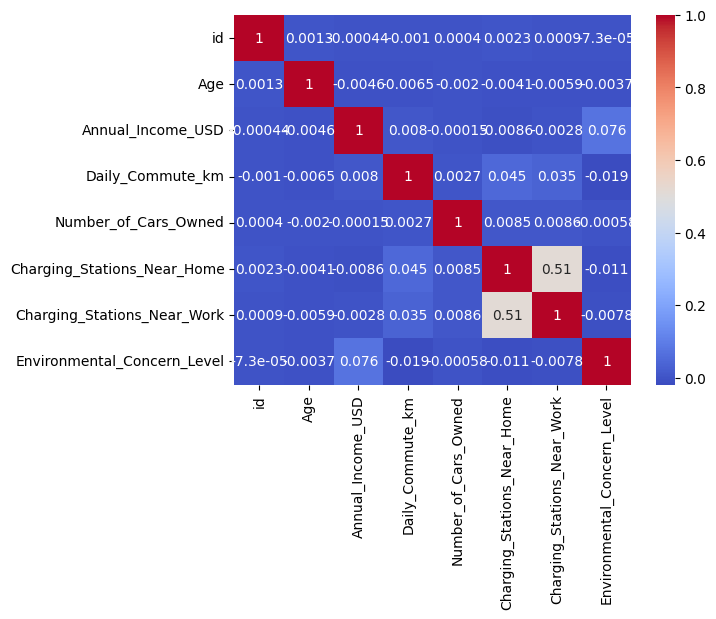

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation heatmap
sns.heatmap(
    df.select_dtypes("number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

In [17]:
"""
Number_of_Cars_Owned: [2 1 4 3]
Environmental_Concern_Level: [1. 4. 5. 3. 2.]
Gender: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
City_Type: <StringArray>
['Suburban', 'Rural', 'Urban']
Length: 3, dtype: str
Current_Car_Type: <StringArray>
['Sedan', 'SUV', 'Hatchback', 'Truck']
Length: 4, dtype: str
Home_Charging_Possible: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Subsidy_Available: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Range_Anxiety_Level: <StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
Will_Buy_EV: <StringArray>
['No', 'Yes']
"""

will_buy_ev_mapping = {"No": 0, "Yes": 1}
df["Will_Buy_EV"] = df["Will_Buy_EV"].map(will_buy_ev_mapping)

In [18]:
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,0
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,0
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,1
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,0
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,0


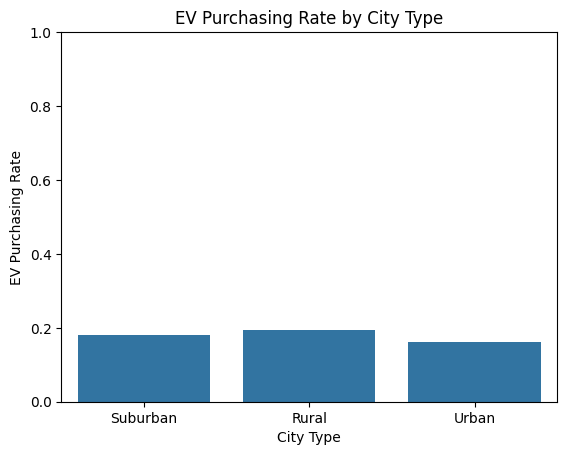

In [19]:
"""
<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxiety_Level          668665 non-null  str    
 14  Will_Buy_EV                  668665 non-null  str    

"""


# Create bar plot
sns.barplot(
    data=df,
    x="City_Type",
    y="Will_Buy_EV",
    errorbar=None
)

plt.title("EV Purchasing Rate by City Type")
plt.xlabel("City Type")
plt.ylabel("EV Purchasing Rate")
plt.ylim(0, 1)

plt.show()